# Mendeley end-to-end test: does the detector work on whole fields?

**ELI5.** The detector learned from small pictures where one cell fills the frame. Mendeley photos are big slides with hundreds of cells on them, and each photo has one label for the whole slide (Negative, LSIL, HSIL or SCC). The detector never trained on Mendeley, so this is a fair exam.

For each photo we slide a small window across the whole slide, let the detector circle and grade every cell it sees, merge the duplicate circles where windows overlap, and take the **worst** grade found as the verdict for the slide. Then we compare that verdict to Mendeley's real label.

**Before you run anything**
1. Turn the GPU on first (Settings, Accelerator, GPU T4 x2). Turning it on later restarts the kernel.
2. Attach two inputs: the Mendeley dataset, and the Kaggle Dataset that holds your three `.pt` weight files.
3. Run the cells top to bottom. Cell 5 is the long one. `SAMPLE_PER_CLASS = 10` keeps the first run to a few minutes. Set it to `None` for all 962 photos once the picture check in cell 4 looks sane.

In [1]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 3.7 MB/s eta 0:00:00


## 1. Helper functions (no model needed)

The severity ranking decides which detection counts as "worst". `verdict()` takes every detection above a confidence threshold and returns the most severe class. If nothing above the threshold is abnormal, the slide is called Negative.

In [2]:
SEVERITY_RANK = {"Negative": 0, "ASC-US": 1, "LSIL": 2, "ASC-H": 3, "HSIL": 4, "SCC": 5}

def short(name):
    # CRIC's long folder name becomes "Negative"; other class names are already short.
    return "Negative" if name.startswith("Negative") else name

def mendeley_true_label(folder_name):
    f = folder_name.lower()
    if f.startswith("negative"): return "Negative"
    if f.startswith("low squamous"): return "LSIL"
    if f.startswith("high squamous"): return "HSIL"
    if f.startswith("squamous cell"): return "SCC"
    raise ValueError(f"Unrecognised Mendeley folder: {folder_name}")

def tile_starts(length, tile, stride):
    last = max(length - tile, 0)
    starts = list(range(0, last + 1, stride))
    if starts[-1] != last:
        starts.append(last)
    return starts

def verdict(dets, thr, names):
    # dets: list of (confidence, class_index). Returns the worst class above thr.
    best = "Negative"
    for conf, cls in dets:
        if conf >= thr:
            n = short(names[cls])
            if SEVERITY_RANK[n] > SEVERITY_RANK[best]:
                best = n
    return best

## 2. Find the Mendeley photos and the trained weights

Instead of hardcoding paths, this searches `/kaggle/input`. It opens every `.pt` file it finds and keeps only the ones with 6 classes. That drops the Stage 1 cell-finder, which only knows one class ("cell") and can't grade severity. Whatever you named the other files, they'll be picked up.

In [3]:
import os, glob
from ultralytics import YOLO

INPUT_ROOT = "/kaggle/input"

mendeley_root = None
for dirpath, dirnames, filenames in os.walk(INPUT_ROOT):
    if "Negative for Intraepithelial malignancy" in dirnames:
        mendeley_root = dirpath
        break
assert mendeley_root, "Mendeley dataset not found: attach it under Add Input."
print("Mendeley root:", mendeley_root)

pt_files = sorted(glob.glob(f"{INPUT_ROOT}/**/*.pt", recursive=True))
print(f"\nFound {len(pt_files)} .pt files:")
for p in pt_files:
    print("  ", p)

models = {}
for p in pt_files:
    m = YOLO(p)
    if len(m.names) == 6:
        models[p] = m
        print(f"\nSEVERITY MODEL (6 classes): {p}")
        print("  classes:", [short(n) for n in m.names.values()])
    else:
        print(f"\nskipped (not a 6-class model, {len(m.names)} class): {p}")
assert models, "No 6-class severity weights found. Check the weights dataset is attached."

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Mendeley root: /kaggle/input/datasets/blank1508/mendeley-lbc-cervical-cancer

Found 3 .pt files:
   /kaggle/input/datasets/wagnermushayija/cervigrade-cell-boxes/stage1_cellfinder_best.pt
   /kaggle/input/datasets/wagnermushayija/cervigrade-cell-boxes/stage2_severity_best.pt
   /kaggle/input/datasets/wagnermushayija/cervigrade-cell-boxes/stage2_severity_oversampled_best.pt

skipped (not a 6-class model, 1 class): /kaggle/input/datasets/wagnermushayija/cervigrade-cell-boxes/stage1_cellfinder_best.pt

SEVERITY MODEL (6 classes): /kaggle/input/datasets/wagnermushayija/cervigrade-cell-boxes/stage2_severity_best.pt
  classes: ['ASC-H', 'ASC-US', 'HSIL', 'LSIL', 'Negative', 'SCC']

SEVERITY MODEL (6 class

## 3. Build the list of photos to test

Each photo's true label comes from its folder name. `SAMPLE_PER_CLASS` takes that many photos from each class with a fixed seed, so reruns use the same photos.

In [4]:
import random
import pandas as pd

SAMPLE_PER_CLASS = 10     # set to None to run all 962 photos
SEED = 42

rows = []
for folder in sorted(os.listdir(mendeley_root)):
    fdir = os.path.join(mendeley_root, folder)
    if not os.path.isdir(fdir):
        continue
    try:
        true = mendeley_true_label(folder)
    except ValueError:
        continue
    for fname in os.listdir(fdir):
        if fname.lower().endswith((".jpg", ".jpeg", ".png")):
            rows.append({"path": os.path.join(fdir, fname), "true": true})

mend = pd.DataFrame(rows)
print("All photos:\n", mend["true"].value_counts())

if SAMPLE_PER_CLASS:
    mend = (mend.groupby("true", group_keys=False)
                .apply(lambda g: g.sample(min(len(g), SAMPLE_PER_CLASS), random_state=SEED))
                .reset_index(drop=True))
print("\nTesting on:\n", mend["true"].value_counts())

All photos:
 true
Negative    612
HSIL        163
LSIL        113
SCC          74
Name: count, dtype: int64

Testing on:
 true
HSIL        10
LSIL        10
Negative    10
SCC         10
Name: count, dtype: int64


/tmp/ipykernel_22/2229935840.py:25: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), SAMPLE_PER_CLASS), random_state=SEED))


## 4. The detector: slide a window over the field, then check a few pictures by eye

`TILE = 224` matches the detector's training size, so the pixels are not shrunk. `STRIDE = 112` overlaps the windows by half, so a cell cut by one window edge shows whole in the next. Circles found twice are merged with non-maximum suppression.

Always look at the pictures before trusting any number. If the boxes land on cells and the grades look plausible, the metrics in cell 5 mean something.

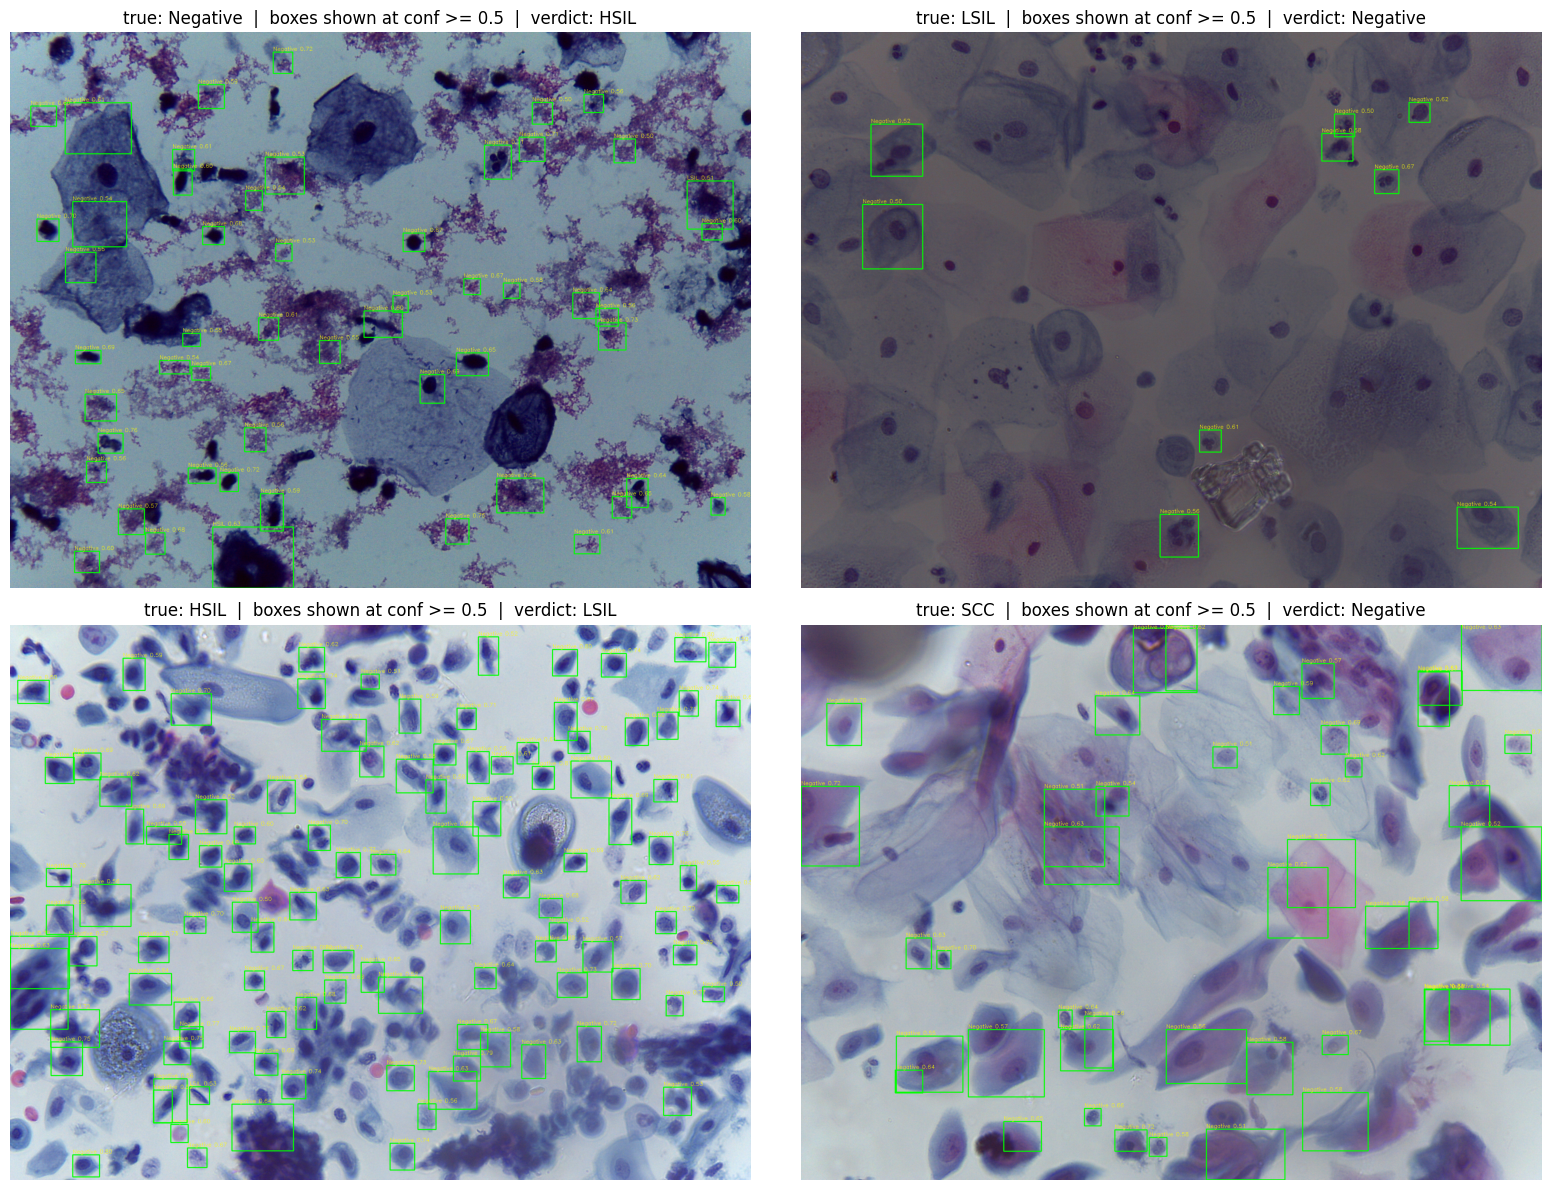

In [5]:
import cv2, time
import numpy as np
import torch
from torchvision.ops import nms
import matplotlib.pyplot as plt

TILE, STRIDE = 224, 112
LOW_CONF = 0.25   # keep everything above this; thresholds are swept later

def detect_field(model, img_bgr, conf=LOW_CONF):
    H, W = img_bgr.shape[:2]
    tiles, offsets = [], []
    for y in tile_starts(H, TILE, STRIDE):
        for x in tile_starts(W, TILE, STRIDE):
            tiles.append(img_bgr[y:y + TILE, x:x + TILE])
            offsets.append((x, y))
    results = model.predict(tiles, imgsz=224, conf=conf, verbose=False, batch=64)
    boxes, scores, classes = [], [], []
    for r, (ox, oy) in zip(results, offsets):
        if r.boxes is None or len(r.boxes) == 0:
            continue
        xyxy = r.boxes.xyxy.cpu().numpy().copy()
        xyxy[:, [0, 2]] += ox
        xyxy[:, [1, 3]] += oy
        boxes.append(xyxy)
        scores.append(r.boxes.conf.cpu().numpy())
        classes.append(r.boxes.cls.cpu().numpy().astype(int))
    if not boxes:
        return np.zeros((0, 4)), np.zeros(0), np.zeros(0, dtype=int)
    boxes = np.concatenate(boxes); scores = np.concatenate(scores); classes = np.concatenate(classes)
    keep = nms(torch.tensor(boxes), torch.tensor(scores), 0.5).numpy()
    return boxes[keep], scores[keep], classes[keep]

# Picture check: one photo per true class, using the first severity model
first_path, first_model = next(iter(models.items()))
CHECK_THR = 0.5
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for ax, cls in zip(axes.ravel(), ["Negative", "LSIL", "HSIL", "SCC"]):
    row = mend[mend["true"] == cls].iloc[0]
    img = cv2.imread(row["path"])
    boxes, scores, classes = detect_field(first_model, img)
    vis = img.copy()
    for (x1, y1, x2, y2), s, c in zip(boxes, scores, classes):
        if s < CHECK_THR:
            continue
        cv2.rectangle(vis, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)
        cv2.putText(vis, f"{short(first_model.names[c])} {s:.2f}", (int(x1), max(int(y1) - 4, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 1)
    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    ax.set_title(f"true: {cls}  |  boxes shown at conf >= {CHECK_THR}  |  "
                 f"verdict: {verdict(list(zip(scores, classes)), CHECK_THR, first_model.names)}")
    ax.axis("off")
plt.tight_layout()
plt.savefig("mendeley_picture_check.png", dpi=110)
plt.show()

## 5. Run the detector on every selected photo

Detections are stored once at a low threshold. The next cell then tries stricter thresholds without re-running the detector. The timing line tells you how long all 962 photos would take.

In [6]:
all_dets = {}   # (weights path, photo path) -> list of (conf, class_index)

for wpath, model in models.items():
    t0 = time.time()
    for i, row in mend.iterrows():
        img = cv2.imread(row["path"])
        _, scores, classes = detect_field(model, img)
        all_dets[(wpath, row["path"])] = list(zip(scores.tolist(), classes.tolist()))
    dt = time.time() - t0
    per_img = dt / len(mend)
    print(f"{os.path.basename(os.path.dirname(wpath))}/{os.path.basename(wpath)}: "
          f"{len(mend)} photos in {dt:.0f}s ({per_img:.2f}s/photo, "
          f"about {per_img * 962 / 60:.0f} min for all 962)")

cervigrade-cell-boxes/stage2_severity_best.pt: 40 photos in 16s (0.41s/photo, about 7 min for all 962)
cervigrade-cell-boxes/stage2_severity_oversampled_best.pt: 40 photos in 14s (0.35s/photo, about 6 min for all 962)


## 6. Results

For each weights file and each confidence threshold, the verdict for a slide is the worst class found above that threshold.

- **4-way exact match** is the slide verdict equal to the true label.
- **Referral sensitivity** treats any abnormal verdict (ASC-US and up) as "refer" and asks what share of truly abnormal slides were caught. This is the number a screening tool lives or dies on.
- **Referral specificity** is the share of truly Negative slides correctly left alone.

A low threshold catches more but over-calls, because one stray false circle on a slide with hundreds of cells is enough to raise the verdict. A high threshold does the reverse. Expect a trade-off, not a single best setting.

In [7]:
THRESHOLDS = [0.25, 0.4, 0.5, 0.6, 0.7]
ORDER = ["Negative", "ASC-US", "LSIL", "ASC-H", "HSIL", "SCC"]

for wpath, model in models.items():
    print("=" * 78)
    print("WEIGHTS:", wpath)
    summary = []
    for thr in THRESHOLDS:
        preds = [verdict(all_dets[(wpath, p)], thr, model.names) for p in mend["path"]]
        true = mend["true"].tolist()
        exact = np.mean([a == b for a, b in zip(true, preds)])
        is_ab_true = np.array([t != "Negative" for t in true])
        is_ab_pred = np.array([p != "Negative" for p in preds])
        sens = (is_ab_pred & is_ab_true).sum() / max(is_ab_true.sum(), 1)
        spec = ((~is_ab_pred) & (~is_ab_true)).sum() / max((~is_ab_true).sum(), 1)
        scc_true = np.array([t == "SCC" for t in true])
        scc_hit = np.array([p in ("SCC", "HSIL") for p in preds])
        scc_catch = (scc_hit & scc_true).sum() / max(scc_true.sum(), 1)
        summary.append({"threshold": thr, "4-way exact match": round(exact, 3),
                        "referral sensitivity": round(sens, 3),
                        "referral specificity": round(spec, 3),
                        "true SCC called SCC/HSIL": round(scc_catch, 3)})
    print(pd.DataFrame(summary).to_string(index=False))

    thr_show = 0.5
    preds = [verdict(all_dets[(wpath, p)], thr_show, model.names) for p in mend["path"]]
    ct = pd.crosstab(mend["true"], pd.Series(preds, name="predicted verdict"))
    ct = ct.reindex(index=["Negative", "LSIL", "HSIL", "SCC"], columns=ORDER, fill_value=0)
    print(f"\nConfusion table at threshold {thr_show} (rows = true label, columns = verdict):")
    print(ct)

WEIGHTS: /kaggle/input/datasets/wagnermushayija/cervigrade-cell-boxes/stage2_severity_best.pt
 threshold  4-way exact match  referral sensitivity  referral specificity  true SCC called SCC/HSIL
      0.25              0.175                 0.733                   0.0                       0.1
      0.40              0.200                 0.533                   0.2                       0.1
      0.50              0.225                 0.300                   0.5                       0.0
      0.60              0.150                 0.033                   0.5                       0.0
      0.70              0.225                 0.000                   0.9                       0.0

Confusion table at threshold 0.5 (rows = true label, columns = verdict):
predicted verdict  Negative  ASC-US  LSIL  ASC-H  HSIL  SCC
true                                                       
Negative                  5       0     2      0     3    0
LSIL                      6       0     4      0    

## How to read this

- Start with `mendeley_picture_check.png`. Boxes sitting on cells with sensible labels means the tiling approach is working. Boxes on background, or hundreds of boxes everywhere, means the scale or colour mismatch between CRIC and Mendeley is too large and the numbers below are noise.
- Compare the two weights files. The oversampled one should catch more SCC.
- Whatever the result, it goes in the writeup as is. A detector trained only on CRIC meeting a different lab's stain and microscope is a real domain-shift test, and a weak score here is a finding, not a failure.